In [1]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import sys
sys.path.append('..')
import numpy as np
import random
import os
from models.mnist_encoder_classifier import MNISTEncoderClassifier
from trainers.encoder_classifier_trainer import EncoderClassifierTrainer

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)  

In [3]:
#data_path = "/datasets/cv_datasets/data"
data_path = "../data"



train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(0, translate=(0.1, 0.1)),
    transforms.ToTensor()
])
val_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()


full_train_dataset = datasets.MNIST(root=data_path, train=True, download=False)
test_dataset = datasets.MNIST(root=data_path, train=False, download=False)


train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = TransformedSubset(train_subset, train_transform)
val_dataset = TransformedSubset(val_subset, val_transform)
test_dataset = TransformedSubset(test_dataset, test_transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

Epoch [1] - Train Loss: 0.6974, Train Acc: 0.8816
Epoch [1] - Val Loss: 0.2110, Val Acc: 0.9753, Test Acc: 0.9796
Epoch [2] - Train Loss: 0.2048, Train Acc: 0.9654
Epoch [2] - Val Loss: 0.0994, Val Acc: 0.9842, Test Acc: 0.9877
Epoch [3] - Train Loss: 0.1215, Train Acc: 0.9740
Epoch [3] - Val Loss: 0.0680, Val Acc: 0.9848, Test Acc: 0.9873
Epoch [4] - Train Loss: 0.0918, Train Acc: 0.9774
Epoch [4] - Val Loss: 0.0523, Val Acc: 0.9857, Test Acc: 0.9894
Epoch [5] - Train Loss: 0.0748, Train Acc: 0.9809
Epoch [5] - Val Loss: 0.0417, Val Acc: 0.9903, Test Acc: 0.9901
Epoch [6] - Train Loss: 0.0679, Train Acc: 0.9812
Epoch [6] - Val Loss: 0.0364, Val Acc: 0.9889, Test Acc: 0.9910
Epoch [7] - Train Loss: 0.0612, Train Acc: 0.9824
Epoch [7] - Val Loss: 0.0383, Val Acc: 0.9888, Test Acc: 0.9888
Epoch [8] - Train Loss: 0.0540, Train Acc: 0.9843
Epoch [8] - Val Loss: 0.0303, Val Acc: 0.9912, Test Acc: 0.9917
Epoch [9] - Train Loss: 0.0534, Train Acc: 0.9845
Epoch [9] - Val Loss: 0.0302, Val Acc:

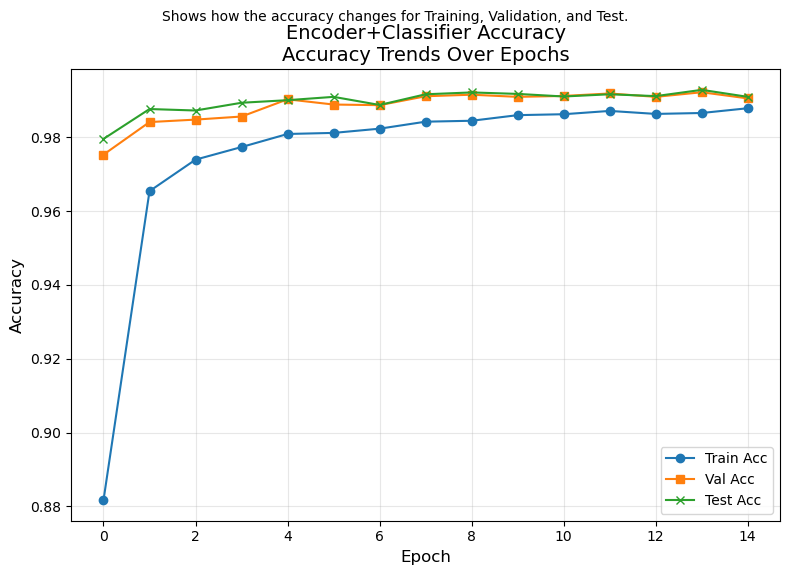

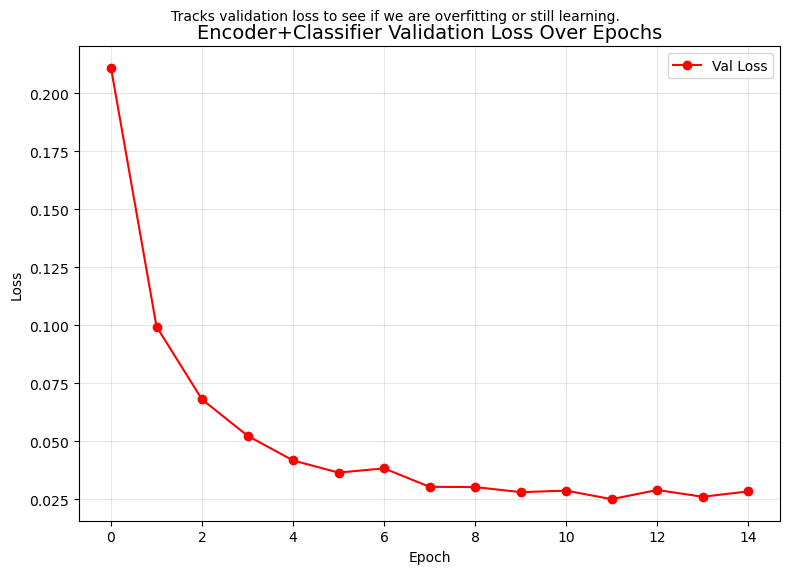

=== Final Encoder+Classifier Metrics ===
Val Loss: 0.0283
Train Acc: 98.79%
Val   Acc: 99.06%
Test  Acc: 99.10%


In [5]:
model = MNISTEncoderClassifier(
input_shape=(1,28,28),
channels=[32,64],
kernel_sizes=[3,3],
strides=[2,2],
paddings=[1,1],
latent_dim=128,
hidden_dims=[1024],
batch_norm_fc=True,
batch_norm_conv=True,
num_classes=10
)

trainer = EncoderClassifierTrainer(
model=model,
train_loader=train_loader,
val_loader=val_loader,
test_loader = test_loader,
device='cuda',
lr=1e-4,
num_epochs=40,
weight_decay=1e-4,
early_stopping=True,
patience=3
)
trainer.train()
trainer.plot_metrics()

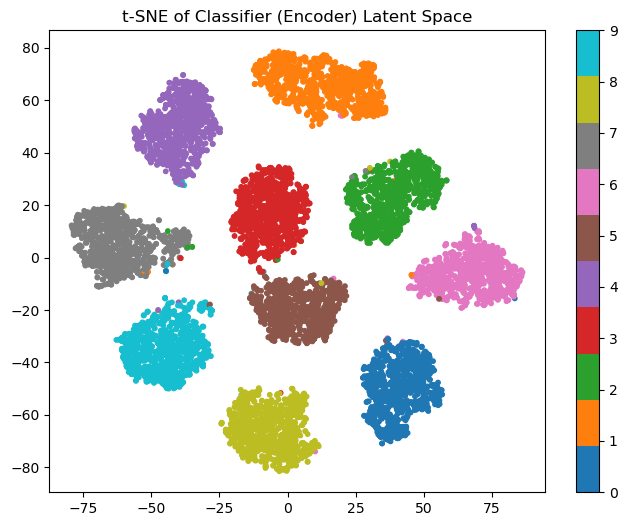

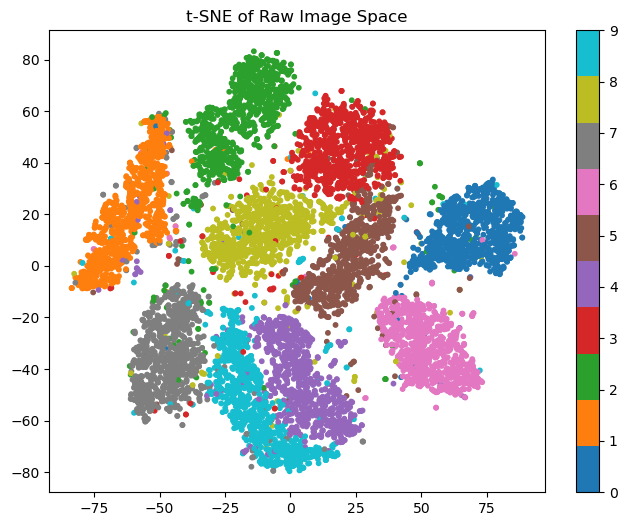

In [6]:
from utils import plot_tsne_classifier
plot_tsne_classifier(model, test_loader, device='cuda')